# Figure 1, Panel G

Lineplots of median ± IQR accesibility log2FC for enhancers, promoters, and insulators over both BAFinh timecourse and BAFinh dose escalation experiments

*Output: panel_g_lineplot.pdf*

# Setup

In [1]:
#load packages
library(tidyverse)
library(patchwork)
library(here)
here::i_am("figures/Figure1/PanelG/panel_G.ipynb")
here()
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/Figure1/PanelG

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



[1] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics"

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      patchwork_1.3.0 lubridate_1.9.4 forcats_1.0.0  
 [5] stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2     readr_2.1.5    
 [9] tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    ba

# Load Data

In [2]:
# read in chromHMM annotations
chromHMM <- read.delim(
  here(
    "figures", "Figure1", "PanelE",
    "consensus_filt_annot_chromHMM.tsv"
  ),
  sep = "\t"
) %>%
  arrange(seqnames, start)

# read in DAR analysis results for all doses and timepoints

dar_0.01 <- read.delim(
  here("inputs", "DARs", "dose_10nM_DARs.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_0.1 <- read.delim(
  here("inputs", "DARs", "dose_100nM_DARs.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_1 <- read.delim(
  here("inputs", "DARs", "dose_1uM_DARs.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_10 <- read.delim(
  here("inputs", "DARs", "dose_10uM_DARs.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_0.5h <- read.delim(
  here("inputs", "DARs", "time_0.5h_DARs.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_1h <- read.delim(
  here("inputs", "DARs", "time_1h_DARs.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_2h <- read.delim(
  here("inputs", "DARs", "time_2h_DARs.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_6h <- read.delim(
  here("inputs", "DARs", "time_6h_DARs.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)

dar_24h <- read.delim(
  here("inputs", "DARs", "time_24h_DARs.tsv"),
  sep = "\t"
) %>%
  arrange(seqnames, start)


# Generate plots

In [3]:

#make lineplots of enhancer, promoter, and insulator median and IQR log2 fold change in accessibility with respect to treatment duration (top) and dose (bottom)

p1 <-  data.frame(
            # make data frame of log2FCs across BAFinh duration
            type = chromHMM$chromHMM_state_slim, 
            t0=0, 
            t0.5=dar_0.5h$logFC, 
            t1=dar_1h$logFC, 
            t2=dar_2h$logFC, 
            t6=dar_6h$logFC, 
            t24=dar_24h$logFC) %>% 
    filter(grepl("Enhancer|Promoter|Insulator", type)) %>% 
    pivot_longer(!type) %>% 
    group_by(type, name) %>% 
    #calculate median, 25th pctile, and 75th pctile log2FC accessibility for each cRE type and timepoint
    summarize(median=median(value), pct_25=quantile(value,.25), pct_75=quantile(value,.75)) %>%
    ggplot(aes(x=factor(name, levels=c("t0", "t0.5", "t1", "t2", "t6", "t24")))) +
        geom_hline(yintercept=0, linetype=2) + 
        geom_ribbon(aes(ymax=pct_75, ymin=pct_25, fill=type, group=type), alpha=.1, color=NA) +
        geom_line(aes(y=median, group=type, color=type)) +
        scale_color_manual(values=c("Enhancer"= "#DAA520","Insulator"= "#AAAAAA","Promoter"= "#268c43"), name='') + 
        scale_fill_manual(values=c("Enhancer"= "#DAA520","Insulator"= "#AAAAAA","Promoter"= "#268c43"), name='') + 
        xlab("BAFinh duration (h)") + ylab("log2 fold change, accessibility\nBAFinh vs vehicle") +
        coord_cartesian(ylim=c(-2.5,.5))


p2 <- data.frame(
        # make data frame of log2FCs across BAFinh dose
        type = chromHMM$chromHMM_state_slim, 
        t0=0, 
        d0.01=dar_0.01$logFC, 
        d0.1=dar_0.1$logFC, 
        d1=dar_1$logFC, 
        d10=dar_10$logFC) %>% 
    filter(grepl("Enhancer|Promoter|Insulator", type)) %>% 
    pivot_longer(!type) %>% 
    group_by(type, name) %>% 
    #calculate median, 25th pctile, and 75th pctile log2FC accessibility for each cRE type and BAFinh dose
    summarize(median=median(value), pct_25=quantile(value,.25), pct_75=quantile(value,.75)) %>%
    ggplot(aes(x=factor(name, levels=c("t0", "d0.01", "d0.1", "d1", "d10")))) +
        geom_hline(yintercept=0, linetype=2) + 
        geom_ribbon(aes(ymax=pct_75, ymin=pct_25, fill=type, group=type), alpha=.1, color=NA) +
        geom_line(aes(y=median, group=type, color=type)) +
        scale_color_manual(values=c("Enhancer"= "#DAA520","Insulator"= "#AAAAAA","Promoter"= "#268c43"), name='') + 
        scale_fill_manual(values=c("Enhancer"= "#DAA520","Insulator"= "#AAAAAA","Promoter"= "#268c43"), name='') + 
        xlab("BAFinh dose (µM)") + ylab("log2 fold change, accessibility\nBAFinh vs vehicle") +
        coord_cartesian(ylim=c(-2.5,.5))

`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.


# Assemble figure panel

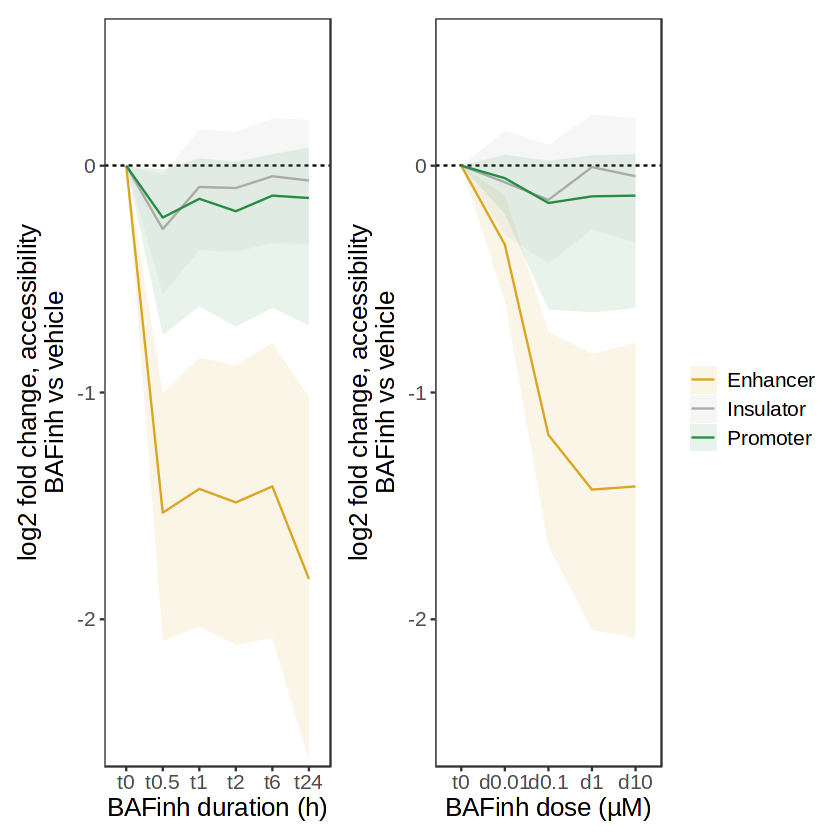

In [4]:
(p1 | p2) + plot_layout(guides="collect")
ggsave("panel_g_lineplot.pdf", height=2.5, width=8)